
# Retail Sales & Profitability Analysis

## Project Overview

This project focuses on analysing retail sales data to understand business performance, profitability, customer behaviour, product performance, and regional trends.

The analysis uses Python, Pandas, SQL, and data visualization techniques to identify meaningful business patterns and generate actionable recommendations.

## Business Objective

The primary objective is to evaluate retail business performance by analysing:

- Overall sales and profitability.
- Regional sales and profit performance.
- Product category and sub-category performance.
- Customer segment behaviour.
- The relationship between discounts and profitability.
- Monthly sales and profit trends.

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib
- SQLite and SQL
- Jupyter Notebook

## Dataset

**Dataset Name:** Sample Superstore

**Source:** Kaggle

https://www.kaggle.com/datasets/vivek468/superstore-dataset-final

**File:** Sample - Superstore.csv


In [53]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import sqlite3 
df = pd.read_csv("Sample - Superstore.csv",encoding = "latin1")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
df.head()

Dataset shape: (9994, 21)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [54]:
df.info

display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())

display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Count")
) 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0


,Missing_Count
Row ID,0
Postal Code,0
Discount,0
Quantity,0
Sales,0
Product Name,0
Sub-Category,0
Category,0
Product ID,0
Region,0


In [55]:
df.columns = ( 
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(r"[^a-z0-9]+","_",regex = True)
      .str.strip("_")
)
print(df.columns.tolist())

['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']


In [56]:
# converting date time into data time format 
for col in ["order_date", "ship_date"]:
    if col in df.columns:
        df[col]= pd.to_datetime(df[col],errors= "coerce")

# converting numeric columns into numeric format 
numeric_cols = [
    col for col in ["sales", "quantity","discount","profit"]
    if col in df.columns 
]

for col in numeric_cols: 
    df[col]= pd.to_numeric(df[col],errors="coerce")
        

# check dataset 
print("Rows:", len(df))

print("Missing values after conversion:")
display(df.isnull().sum().to_frame("Missing_count"))

# check order date range 
if "order_date" in df.columns:
    print(
        "Order date range:",
        df["order_date"].min(),
        "to",
        df["order_date"].max()
    )

display(df.head())




 


                            

Rows: 9994
Missing values after conversion:


,Missing_count
row_id,0
order_id,0
order_date,0
ship_date,0
ship_mode,0
customer_id,0
customer_name,0
segment,0
country,0
city,0


Order date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [57]:
# calculate core businesss KPIs 
total_sales = df["sales"].sum()
total_profit= df["profit"].sum()
total_quantity= df["quantity"].sum()

profit_margin = (
    total_profit/total_sales * 100 
    if total_sales != 0 else np.nan
)

# create a KPI summary table 

kpis = pd.DataFrame(
    [
        ["Total Sales", total_sales],
        ["Total Profit", total_profit],
        ["Total Quantity", total_quantity],
        ["Profit Margin (%)", profit_margin]
    ],
    columns=["Metric", "Value"]
)

display(kpis.round(2))


,Metric,Value
0,Total Sales,2297200.86
1,Total Profit,286397.02
2,Total Quantity,37873.00
3,Profit Margin (%),12.47


In [58]:
# sales profit by region 
if "region" in df.columns:
    region_analysis = (
        df.groupby("region" , as_index=False)
          .agg(
            Sales=("sales","sum"),
            Profit=("profit","sum"),
            Quantity=("quantity","sum"),
            Orders=("order_id","nunique"))

        )

    region_analysis["Profit_Margin_PCT"]=(
            region_analysis["Profit"]
            / region_analysis["Sales"].replace(0,np.nan)* 100 
        )

    display(
            region_analysis.sort_values("Sales",ascending=False).round(2))
            
        

    

    

,region,Sales,Profit,Quantity,Orders,Profit_Margin_PCT
3,West,725457.82,108418.45,12266,1611,14.94
1,East,678781.24,91522.78,10618,1401,13.48
0,Central,501239.89,39706.36,8780,1175,7.92
2,South,391721.90,46749.43,6209,822,11.93


In [59]:
# Category and sub category 

category_analysis = (
    df.groupby("category", as_index=False)
    .agg(
        Sales= ("sales","sum"),
        Profit=("profit","sum"),
        Quantity=("quantity","sum")

    )
)

category_analysis["Profit_Margin_Pct"]=(
    category_analysis["Profit"] / category_analysis["Sales"].replace(0, np.nan) * 100 
)

display(category_analysis.sort_values("Profit",ascending = False).round(2))


,category,Sales,Profit,Quantity,Profit_Margin_Pct
2,Technology,836154.03,145454.95,6939,17.40
1,Office Supplies,719047.03,122490.80,22906,17.04
0,Furniture,741999.80,18451.27,8028,2.49


In [60]:
if "sub_category" in df.columns:
    subcategory_analysis=(
        df.groupby("sub_category",as_index=False).agg(
            Sales=("sales","sum"),
            Profit=("profit","sum"),
            Quantity=("quantity","sum")
        ).sort_values("Profit",ascending = True)
  
    )
    subcategory_analysis["Profit_Margin_Pct"]=(
        subcategory_analysis["Profit"] / subcategory_analysis["Sales"].replace(0,np.nan)*100
    )
    display(subcategory_analysis.round(2))


,sub_category,Sales,Profit,Quantity,Profit_Margin_Pct
16,Tables,206965.53,-17725.48,1241,-8.56
4,Bookcases,114880.00,-3472.56,868,-3.02
15,Supplies,46673.54,-1189.10,647,-2.55
8,Fasteners,3024.28,949.52,914,31.40
11,Machines,189238.63,3384.76,440,1.79
10,Labels,12486.31,5546.25,1400,44.42
2,Art,27118.79,6527.79,3000,24.07
7,Envelopes,16476.40,6964.18,906,42.27
9,Furnishings,91705.16,13059.14,3563,14.24
1,Appliances,107532.16,18138.01,1729,16.87


In [61]:
# customer sagment analysis 
if "segment" in df.columns:
    segment_analysis=(
        df.groupby("segment",as_index = False).agg(
            Sales=("sales","sum"),
            Profit=("profit","sum"),
            Quantity=("quantity","sum"),
            Customers=("customer_id","nunique")
        )
    )
    segment_analysis["Profit_Segment_Pct"]=(
        segment_analysis["Profit"] /
        segment_analysis["Sales"].replace(0,np.nan)*100
    )

    display(
        segment_analysis.sort_values("Sales",ascending=False).round(2)
    )

,segment,Sales,Profit,Quantity,Customers,Profit_Segment_Pct
0,Consumer,1161401.34,134119.21,19521,409,11.55
1,Corporate,706146.37,91979.13,11608,236,13.03
2,Home Office,429653.15,60298.68,6744,148,14.03


In [62]:
# discount analysis 
if "discount" in df.columns:
    df["discount_band"]= pd.cut(
    df["discount"],
    bins=[-np.inf,0,0.10,0.20,0.30,np.inf],
    labels=[
        "No Discount",
        "Up to 10%",
        "10-20%",
        "20-30%",
        "Above 30%"
    ],
    right=True 

    )

    discount_analysis = (
        df.groupby("discount_band", observed = False, as_index=False).agg(
            Sales = ("sales","sum"),
            Profit = ("profit","sum"),
            Quantity = ("quantity","sum")
        )
    )

    discount_analysis["Profit_Margin_Pct"]=(
        discount_analysis["Profit"]
        / discount_analysis["Sales"].replace(0,np.nan)*100 

    )

    display(discount_analysis.round(2))

       




    

,discount_band,Sales,Profit,Quantity,Profit_Margin_Pct
0,No Discount,1087908.47,320987.60,18267,29.51
1,Up to 10%,54369.35,9029.18,373,16.61
2,10-20%,792152.89,91756.30,13858,11.58
3,20-30%,103226.66,-10369.28,849,-10.05
4,Above 30%,259543.49,-125006.78,4526,-48.16


In [63]:
# cleaned data ko SQlite main load karna
import sqlite3 
conn = sqlite3.connect("superstore_analysis.db")
df.to_sql(
    "orders",
    conn,
    if_exists="replace",
    index=False
)
print(
    pd.read_sql_query(
        "SELECT COUNT(*) AS row_count FROM orders",
        conn
    )
)

   row_count
0       9994


In [64]:
query = """
SELECT 
ROUND(SUM(sales),2) AS total_sales,
ROUND(SUM(profit),2) AS total_profit,
ROUND(
100.0 * SUM(profit)/NULLIF(SUM(sales), 0 ),2 
) AS profit_margin_pct
FROM orders;
""" 
display(pd.read_sql_query(query,conn))


,total_sales,total_profit,profit_margin_pct
0,2297200.86,286397.02,12.47


In [65]:
# region wise sales and profit 

query = """
SELECT 
region,ROUND(SUM(sales),2)AS total_sales,
ROUND(SUM(profit),2)AS total_profit
FROM orders
GROUP BY region
ORDER BY total_sales DESC;
"""
display(pd.read_sql_query(query,conn))

,region,total_sales,total_profit
0,West,725457.82,108418.45
1,East,678781.24,91522.78
2,Central,501239.89,39706.36
3,South,391721.91,46749.43


In [66]:
# category with negative profit 
query= """
SELECT 
category,ROUND(SUM(sales),2) AS total_sales,
ROUND(SUM(profit),2) AS total_profit
FROM orders
GROUP BY category
HAVING SUM(profit) < 0 
ORDER BY total_profit;
"""

display(pd.read_sql_query(query,conn))

,category,total_sales,total_profit


In [67]:
# top 10 subcategory profit 

query = """
SELECT 
sub_category,ROUND(SUM(sales),2) AS total_sales,
ROUND(SUM(profit),2) AS total_profit
FROM orders
GROUP BY sub_category
ORDER by total_profit DESC 
lIMIT 10;
"""

display(pd.read_sql_query(query,conn))

,sub_category,total_sales,total_profit
0,Copiers,149528.03,55617.82
1,Phones,330007.05,44515.73
2,Accessories,167380.32,41936.64
3,Paper,78479.21,34053.57
4,Binders,203412.73,30221.76
5,Chairs,328449.10,26590.17
6,Storage,223843.61,21278.83
7,Appliances,107532.16,18138.01
8,Furnishings,91705.16,13059.14
9,Envelopes,16476.40,6964.18


In [68]:
query = """ 
SELECT order_date
FROM orders 
LIMIT 5;
"""
display(pd.read_sql_query(query,conn))

,order_date
0,2016-11-08 00:00:00
1,2016-11-08 00:00:00
2,2016-06-12 00:00:00
3,2015-10-11 00:00:00
4,2015-10-11 00:00:00


In [69]:

query = """
SELECT
    order_date,
    strftime('%Y-%m', order_date) AS parsed_month
FROM orders
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))


,order_date,parsed_month
0,2016-11-08 00:00:00,2016-11
1,2016-11-08 00:00:00,2016-11
2,2016-06-12 00:00:00,2016-06
3,2015-10-11 00:00:00,2015-10
4,2015-10-11 00:00:00,2015-10
5,2014-06-09 00:00:00,2014-06
6,2014-06-09 00:00:00,2014-06
7,2014-06-09 00:00:00,2014-06
8,2014-06-09 00:00:00,2014-06
9,2014-06-09 00:00:00,2014-06


In [70]:
# monthy sales trend 

query = """ 
SELECT 
strftime('%Y-%m' , order_date) AS month,
ROUND(SUM(sales),2) AS total_sales,
ROUND(SUM(profit),2) AS total_profit
FROM orders 
WHERE order_date IS NOT NULL
GROUP BY strftime('%Y-%m',order_date)
ORDER BY month;
"""

display(pd.read_sql_query(query,conn))


,month,total_sales,total_profit
0,2014-01,14236.90,2450.19
1,2014-02,4519.89,862.31
2,2014-03,55691.01,498.73
3,2014-04,28295.35,3488.84
4,2014-05,23648.29,2738.71
5,2014-06,34595.13,4976.52
6,2014-07,33946.39,-841.48
7,2014-08,27909.47,5318.10
8,2014-09,81777.35,8328.10
9,2014-10,31453.39,3448.26


In [71]:
# top 10 customer by sales 


query = """
SELECT
    customer_id,
    customer_name,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM orders
GROUP BY customer_id, customer_name
ORDER BY total_sales DESC
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))


,customer_id,customer_name,total_sales,total_profit
0,SM-20320,Sean Miller,25043.05,-1980.74
1,TC-20980,Tamara Chand,19052.22,8981.32
2,RB-19360,Raymond Buch,15117.34,6976.10
3,TA-21385,Tom Ashbrook,14595.62,4703.79
4,AB-10105,Adrian Barton,14473.57,5444.81
5,KL-16645,Ken Lonsdale,14175.23,806.85
6,SC-20095,Sanjit Chand,14142.33,5757.41
7,HL-15040,Hunter Lopez,12873.30,5622.43
8,SE-20110,Sanjit Engle,12209.44,2650.68
9,CC-12370,Christopher Conant,12129.07,2177.05


In [72]:
# CTE + RANKS 


query = """
WITH subcategory_profit AS (
    SELECT
        category,
        sub_category,
        SUM(profit) AS total_profit
    FROM orders
    GROUP BY category, sub_category
)
SELECT
    category,
    sub_category,
    ROUND(total_profit, 2) AS total_profit,
    RANK() OVER (
        PARTITION BY category
        ORDER BY total_profit DESC
    ) AS profit_rank
FROM subcategory_profit
ORDER BY category, profit_rank;
"""

display(pd.read_sql_query(query, conn))


,category,sub_category,total_profit,profit_rank
0,Furniture,Chairs,26590.17,1
1,Furniture,Furnishings,13059.14,2
2,Furniture,Bookcases,-3472.56,3
3,Furniture,Tables,-17725.48,4
4,Office Supplies,Paper,34053.57,1
5,Office Supplies,Binders,30221.76,2
6,Office Supplies,Storage,21278.83,3
7,Office Supplies,Appliances,18138.01,4
8,Office Supplies,Envelopes,6964.18,5
9,Office Supplies,Art,6527.79,6


## Visulization 


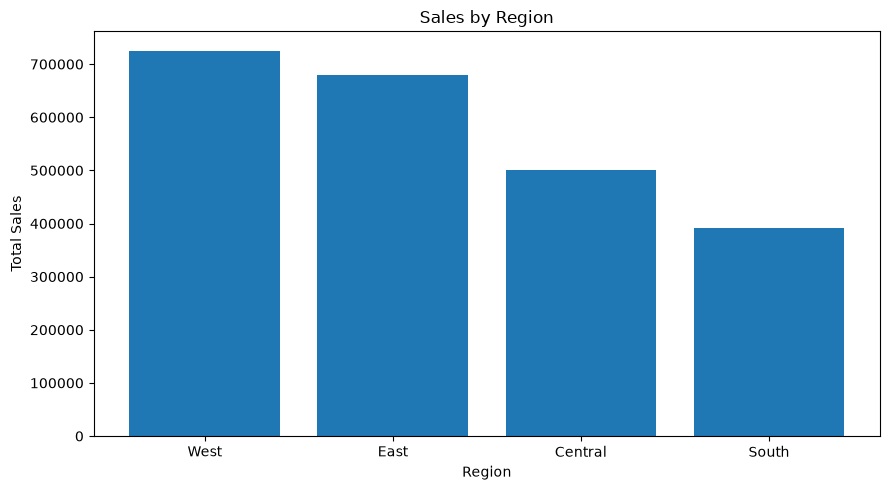

In [73]:

import matplotlib.pyplot as plt

region_plot = region_analysis.sort_values(
    "Sales", ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    region_plot["region"],
    region_plot["Sales"]
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()



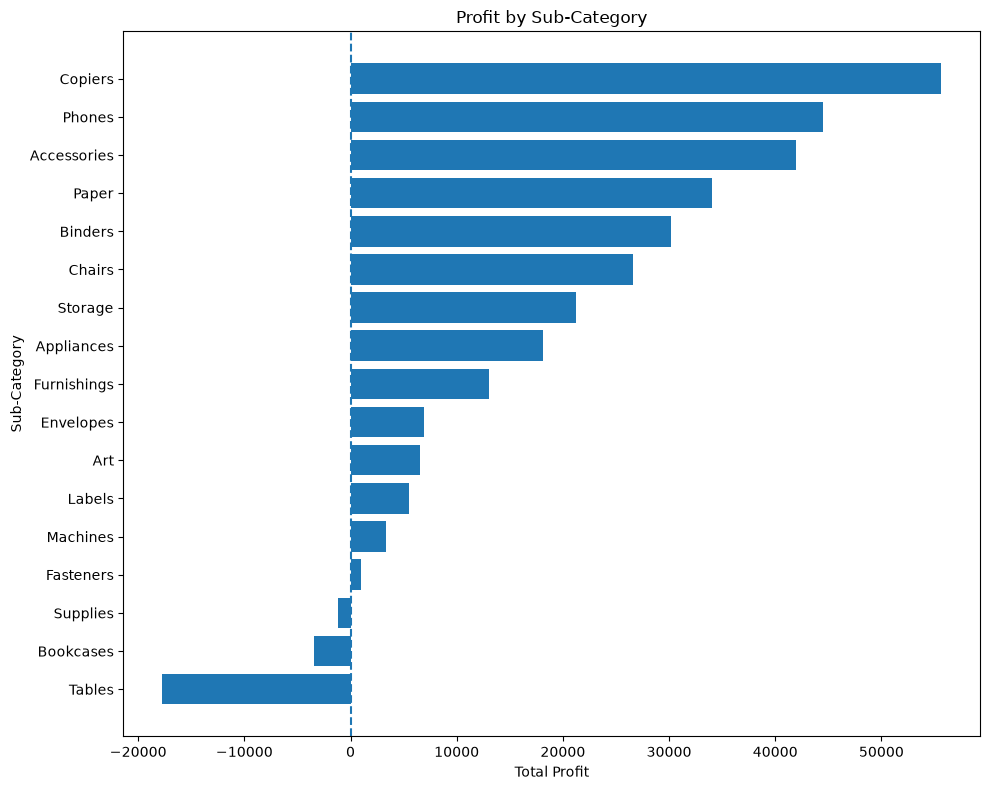

In [74]:

plot_data = subcategory_analysis.sort_values("Profit")

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data["sub_category"],
    plot_data["Profit"]
)

plt.axvline(0, linestyle="--")
plt.title("Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()


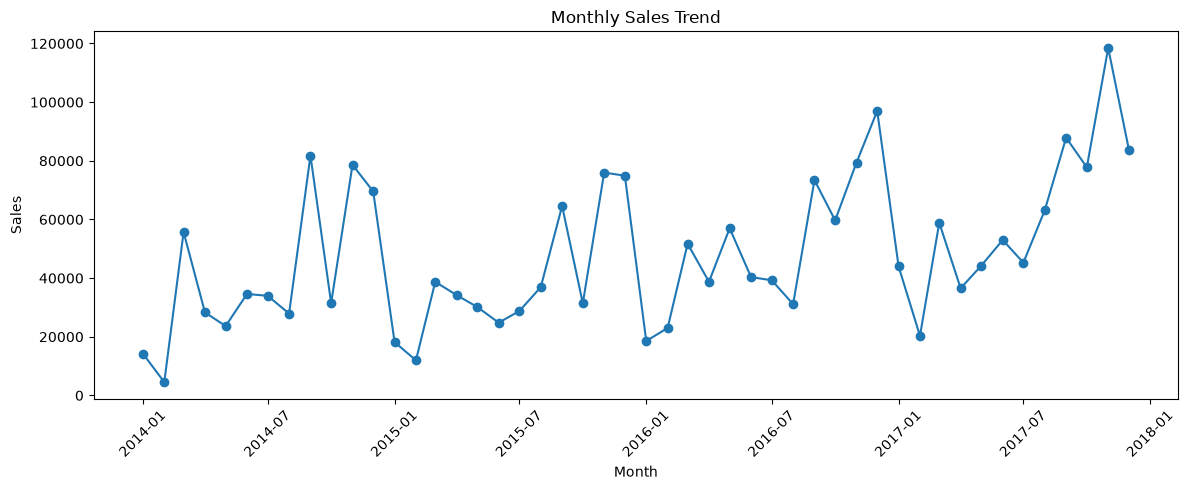

In [75]:

monthly_sales = (
    df.dropna(subset=["order_date"])
      .assign(
          month=lambda x: (
              x["order_date"].dt.to_period("M").dt.to_timestamp()
          )
      )
      .groupby("month", as_index=False)
      .agg(
          Sales=("sales", "sum"),
          Profit=("profit", "sum")
      )
      .sort_values("month")
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


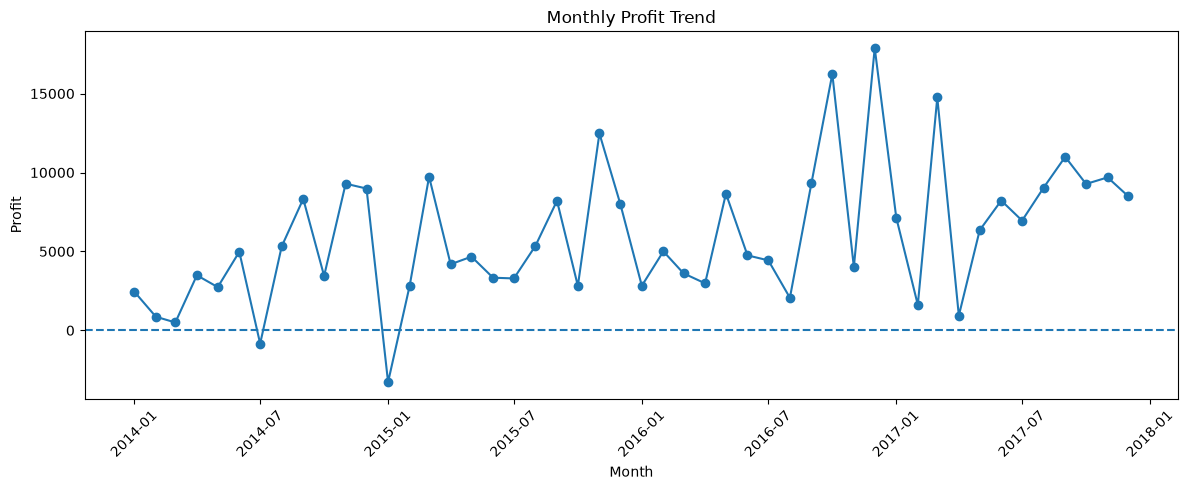

In [76]:

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["Profit"],
    marker="o"
)

plt.axhline(0, linestyle="--")
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [77]:

print("Overall KPIs")
display(kpis.round(2))

print("Region performance")
display(region_analysis.round(2))

print("Category performance")
display(category_analysis.round(2))

# Bottom 3 least profitable sub-categories
bottom_3 = subcategory_analysis.nsmallest(3, "Profit")

# Top 3 most profitable sub-categories
top_3 = subcategory_analysis.nlargest(3, "Profit")

print("Bottom 3 sub-categories")
display(bottom_3.round(2))

print("Top 3 sub-categories")
display(top_3.round(2))


print("Customer segment performance")
display(segment_analysis.round(2))

print("Discount analysis")
display(discount_analysis.round(2))


Overall KPIs


,Metric,Value
0,Total Sales,2297200.86
1,Total Profit,286397.02
2,Total Quantity,37873.00
3,Profit Margin (%),12.47


Region performance


,region,Sales,Profit,Quantity,Orders,Profit_Margin_PCT
0,Central,501239.89,39706.36,8780,1175,7.92
1,East,678781.24,91522.78,10618,1401,13.48
2,South,391721.90,46749.43,6209,822,11.93
3,West,725457.82,108418.45,12266,1611,14.94


Category performance


,category,Sales,Profit,Quantity,Profit_Margin_Pct
0,Furniture,741999.80,18451.27,8028,2.49
1,Office Supplies,719047.03,122490.80,22906,17.04
2,Technology,836154.03,145454.95,6939,17.40


... (4 outputs left out)

Customer segment performance


,segment,Sales,Profit,Quantity,Customers,Profit_Segment_Pct
0,Consumer,1161401.34,134119.21,19521,409,11.55
1,Corporate,706146.37,91979.13,11608,236,13.03
2,Home Office,429653.15,60298.68,6744,148,14.03


Discount analysis


,discount_band,Sales,Profit,Quantity,Profit_Margin_Pct
0,No Discount,1087908.47,320987.60,18267,29.51
1,Up to 10%,54369.35,9029.18,373,16.61
2,10-20%,792152.89,91756.30,13858,11.58
3,20-30%,103226.66,-10369.28,849,-10.05
4,Above 30%,259543.49,-125006.78,4526,-48.16


### Cleaned CSV export

In [78]:

df.to_csv("superstore_cleaned.csv", index=False)

print("Cleaned CSV exported.")


Cleaned CSV exported.



# Key Business Findings

## 1. Overall Performance

The business generated approximately $2.30 million in sales and $286.40 thousand in profit, with an overall profit margin of 12.47%.

## 2. Regional Performance

West generated the highest sales, while South recorded the lowest. West also achieved the highest regional profit margin.

## 3. Category Performance

Technology was the most profitable category, followed by Office Supplies. Furniture generated the lowest profit and had a significantly lower profit margin.

## 4. Product Performance

Copiers generated the highest sub-category profit. Tables recorded the largest loss, followed by Bookcases and Supplies.

## 5. Customer Segments

Consumer generated the highest sales and profit. Home Office achieved the highest profit margin at 14.03%.

## 6. Discount Analysis

Profit margins declined across higher discount bands. Transactions with discounts above 30% showed a negative profit margin of -48.16%.

## 7. Monthly Trends

Sales fluctuated throughout the 2014–2017 period. November 2017 recorded the highest monthly sales in the dataset at $118,447.82.

Sales and profit did not always move together. Some months recorded negative profit despite positive sales.



# Business Recommendations

1. **Improve Loss-Making Products:** Investigate the reasons behind losses in Tables and Bookcases before changing prices or discontinuing products.

2. **Strengthen Regional Strategies:** Study successful sales and profitability strategies in the West region and investigate weaker regional performance.

3. **Review Discount Policies:** Evaluate high-discount transactions at the product level and establish more effective discount controls.

4. **Focus on Profitable Customer Segments:** Identify opportunities to improve customer engagement and profitability in the Home Office segment while maintaining Consumer segment performance.

5. **Monitor Monthly Performance:** Track sales and profit together to identify seasonal patterns and potential loss-making periods.

6. **Improve Product Decisions:** Use product-level profitability analysis to support pricing, inventory, and promotional decisions.



# Limitations

- Observational data does not prove causation.
- Product costs and operating expenses may not be fully represented.
- Historical trends do not guarantee future performance.
- Recommendations require further validation.

# Conclusion

The analysis provided an overview of retail business performance across regions, product categories, customer segments, discounts, and monthly trends.

The results highlighted differences between sales performance and profitability. Technology and the West region were strong contributors, while certain sub-categories, particularly Tables, showed profitability challenges.

The analysis also indicated an association between higher discount bands and lower profit margins.

These findings can help businesses make more informed decisions regarding product performance, discount strategies, regional planning, and customer segments.
